In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from pathlib import Path

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
PROJECT_ROOT  = Path.cwd()

if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "SkyCity Auckland Restaurants & Bars.csv"

df = pd.read_csv(DATA_PATH)

In [3]:
df.head()

,CuisineType,RestaurantID,RestaurantName,Segment,Subregion,GrowthFactor,AOV,MonthlyOrders,InStoreOrders,InStoreRevenue,...,DeliveryCostPerOrder,SD_DeliveryTotalCost,InStoreNetProfit,UberEatsNetProfit,DoorDashNetProfit,SelfDeliveryNetProfit,InStoreShare,UE_share,DD_share,SD_share
0,Burgers,25731,Urban Burgers House,Cafe,North Shore,1.03,43.97,668,197,8662.09,...,3.25,458.25,3682.14,1352.45,752.78,2177.19,0.42,0.45,0.25,0.3
1,Burgers,25123,Urban Burgers Diner,QSR,South Auckland,1.05,40.45,1388,259,10476.55,...,4.72,1600.08,3605.72,1318.61,731.99,3119.38,0.23,0.45,0.25,0.3
2,Burgers,25177,King Burgers Eatery,Cafe,West Auckland,1.04,40.03,1717,524,20975.72,...,3.25,1163.50,7810.95,1555.90,863.42,4172.99,0.44,0.45,0.25,0.3
3,Burgers,25540,Classic Burgers Tavern,QSR,North Shore,1.03,36.28,1083,216,7836.48,...,0.89,231.40,2546.02,-72.25,-40.20,2833.26,0.25,0.45,0.25,0.3
4,Burgers,25258,Lucky Burgers Bistro,Cafe,South Auckland,1.05,34.34,1230,261,8962.74,...,2.66,774.06,3093.09,226.17,125.53,2674.56,0.27,0.45,0.25,0.3


In [4]:
df.shape

(1696, 30)

In [5]:
aliases = {
    "InStoreOrdersCount": "InStoreOrders",
    "UberEatsOrdersCount": "UberEatsOrders",
    "DoorDashOrdersCount": "DoorDashOrders",
    "SelfDeliveryOrdersCount": "SelfDeliveryOrders",
    "DeliveryCostOrders": "DeliveryCostPerOrder",
}

for old_name, new_name in aliases.items():
    if old_name in df.columns and new_name not in df.columns:
        df = df.rename(columns={old_name: new_name})
        
print(df.columns.tolist())

['CuisineType', 'RestaurantID', 'RestaurantName', 'Segment', 'Subregion', 'GrowthFactor', 'AOV', 'MonthlyOrders', 'InStoreOrders', 'InStoreRevenue', 'UberEatsOrders', 'DoorDashOrders', 'SelfDeliveryOrders', 'UberEatsRevenue', 'DoorDashRevenue', 'SelfDeliveryRevenue', 'COGSRate', 'OPEXRate', 'CommissionRate', 'DeliveryRadiusKM', 'DeliveryCostPerOrder', 'SD_DeliveryTotalCost', 'InStoreNetProfit', 'UberEatsNetProfit', 'DoorDashNetProfit', 'SelfDeliveryNetProfit', 'InStoreShare', 'UE_share', 'DD_share', 'SD_share']


In [6]:
categorical_features = [
    "CuisineType",
    "Segment",
    "Subregion",
]

numeric_features = [
    "GrowthFactor",
    "AOV",
    "MonthlyOrders",
    "InStoreOrders",
    "UberEatsOrders",
    "DoorDashOrders",
    "SelfDeliveryOrders",
    "COGSRate",
    "OPEXRate",
    "CommissionRate",
    "DeliveryRadiusKM",
    "DeliveryCostPerOrder",
]

profit_columns = [
    "InStoreNetProfit",
    "UberEatsNetProfit",
    "DoorDashNetProfit",
    "SelfDeliveryNetProfit"
]

feature_columns = categorical_features + numeric_features

required_columns = feature_columns + profit_columns
missing_columns = [c for c in required_columns if c not in df.columns]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

X = df[feature_columns].copy()
y = df[profit_columns].sum(axis=1).astype(float)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Target name: TotalNetProfit")

Feature shape: (1696, 15)
Target shape: (1696,)
Target name: TotalNetProfit


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 1356
Testing records: 340


In [8]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [9]:
models = {
    "Dummy Regressor": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv = cv,
        scoring = {
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },n_jobs=1
    )
    
    cv_results.append({
        "Model": name,
        "CV MAE": -scores["test_mae"].mean(),
        "CV RMSE": -scores["test_rmse"].mean(),
        "CV R2": scores["test_r2"].mean()
    })
    
cv_df = pd.DataFrame(cv_results).sort_values("CV MAE")

display(cv_df)

,Model,CV MAE,CV RMSE,CV R2
2,Random Forest,828.324511,1145.657621,0.961508
3,Gradient Boosting,1053.735948,1407.897967,0.941997
1,Linear Regression,1413.963335,1955.660419,0.888010
0,Dummy Regressor,4645.443430,5867.717064,-0.005639


In [10]:
best_model_name = cv_df.iloc[0]["Model"]

best_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", models[best_model_name])
])

best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Best model:", best_model_name)
print(f"Test MAE: {mae:,.2f}")
print(f"Test RMSE:  { rmse:,.2f}")
print(f"Test R2: {r2:.4f}")

Best model: Random Forest
Test MAE: 867.69
Test RMSE:  1,171.70
Test R2: 0.9573


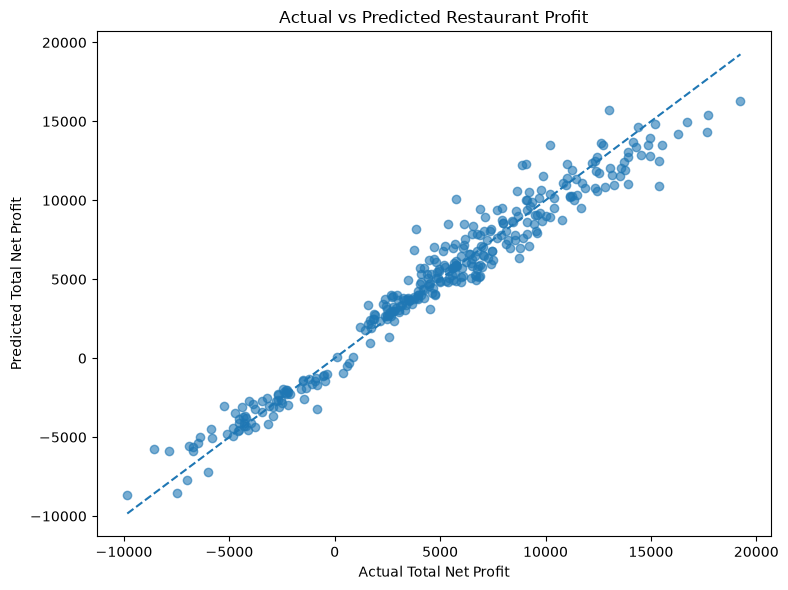

In [11]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.6)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle = "--"
)

plt.xlabel("Actual Total Net Profit")
plt.ylabel("Predicted Total Net Profit")
plt.title("Actual vs Predicted Restaurant Profit")
plt.tight_layout()
plt.show()

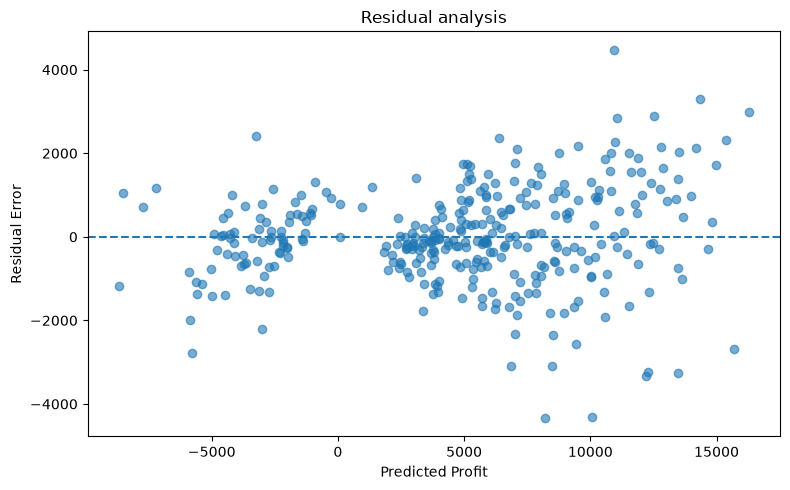

In [12]:
residuals = y_test - y_pred

plt.figure(figsize=(8,5))
plt.scatter(y_pred, residuals, alpha=0.6)

plt.axhline(y=0, linestyle= "--")

plt.xlabel("Predicted Profit")
plt.ylabel("Residual Error")
plt.title("Residual analysis")
plt.tight_layout()
plt.show()

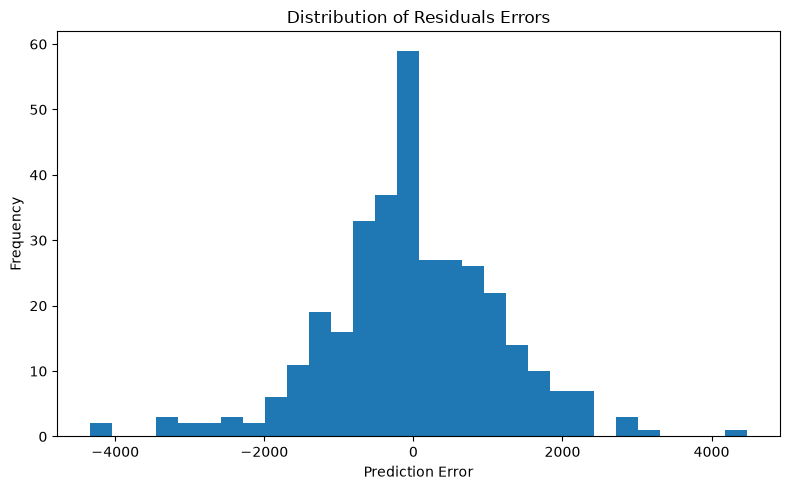

In [13]:
plt.figure(figsize=(8,5))
plt.hist(residuals, bins=30)

plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals Errors")
plt.tight_layout()
plt.show()

In [14]:
importance  = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
}).sort_values("Importance", ascending=False)

display(importance_df)

,Feature,Importance,Std
11,OPEXRate,2981.988354,122.013563
10,COGSRate,888.932009,50.505835
9,SelfDeliveryOrders,753.000290,53.325397
5,MonthlyOrders,535.348179,35.935331
1,Segment,324.960242,32.013543
6,InStoreOrders,302.594425,42.058948
4,AOV,265.809791,27.376265
7,UberEatsOrders,134.779233,14.568423
8,DoorDashOrders,79.199541,12.078812
12,CommissionRate,55.604270,5.389673


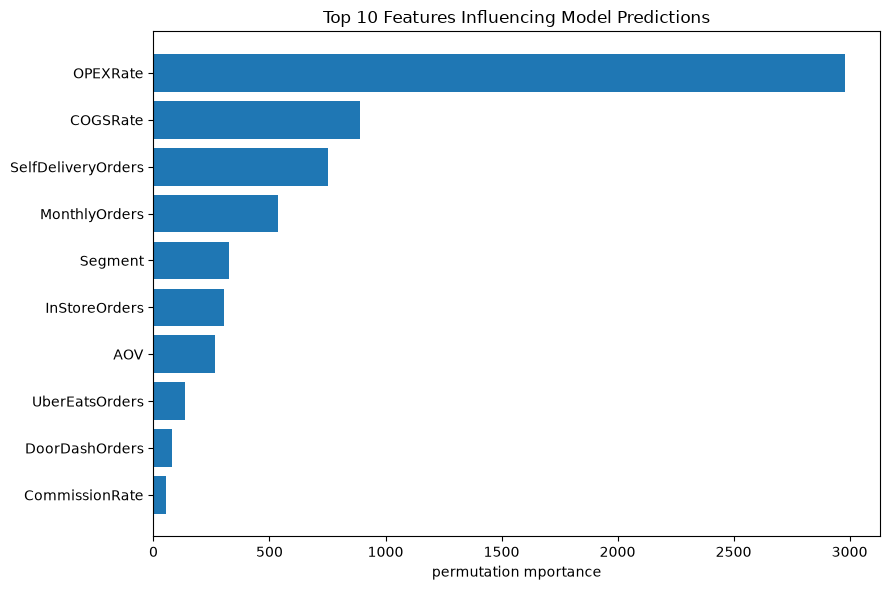

In [15]:
top_features = importance_df.head(10).sort_values("Importance")

plt.figure(figsize=(9,6))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("permutation mportance")
plt.title("Top 10 Features Influencing Model Predictions")
plt.tight_layout()
plt.show()

In [17]:
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "reports"
MODEL_DIR = PROJECT_ROOT / "models"

cv_df.to_csv(
    OUTPUT_DIR / "cross_validation_results.csv",
    index = False
)

importance_df.to_csv(
    OUTPUT_DIR / "feature_importance.csv",
    index=False
)

evaluation_summary = pd.DataFrame([{
    "Best Model": best_model_name,
    "Test MAE": mae,
    "Test RMSE": rmse,
    "test R2": r2
}])

evaluation_summary.to_csv(
    OUTPUT_DIR / "final_model_evaluation.csv",
    index=False
)

joblib.dump(
    {
        "model": best_model,
        "model_name": best_model_name,
        "features": feature_columns,
        "target": "TotalNetProfit"
    },
    MODEL_DIR / "restaurant_profit_model.joblib"
)

['c:\\Users\\ganesh\\Desktop\\All Projects\\Restaurant Profitability Analysis ML\\models\\restaurant_profit_model.joblib']